# Ball Game

We have an infinite population. Most persons dont’ have a ball in their hands. At
the initial time, some people have red balls in their hands. There are red and blue
balls on the floor. From time to time, a person with a red ball picks up another red
ball and a blue ball from the floor and gives the two red balls to people without any
balls in their hands. Here we assume that in principle any person can interact with
any other person.

The person keeps the blue ball in their hand (forever).

What’s the state of the population? What’s the processes? How does the stoichiometric vector(s), how the propensity function(s) look like? Which ODE model do
you obtain?

------

## 1. Identify the states
Each person can be in one of three states:
- S(t) : People holding no ball (susceptible).
- R(t) : People holding a red ball.
- B(t) : People holding a blue ball.

We can represent the state of the population by

$$\boxed{x(t)=\begin{pmatrix}S(t)\\R(t)\\B(t)\end{pmatrix}}$$

----

## 2. Understand the process

Look carefully at what happens when a person holding a red ball initiates the process.


1 Red + 2 Empty-Handed $\rightarrow$ 1 Blue + 2 Red

Therefore each event: 

$$
\begin{aligned}
\Delta S&=-2,\\
\Delta R&=+1,\\
\Delta B&=+1.
\end{aligned}
$$

Why does $R$ increase by only one? Because the original red-ball holder gives away their red ball, while two new people receive red balls.

-------

## 3. Construct the stoichiometric vector

The stoichiometric vector tells us how the state changes when one event occurs. With the state ordering $(S,R,B)$, we obtain

$$
\boxed{
\nu=\begin{pmatrix}-2\\1\\1\end{pmatrix}.
}
$$

This is the answer to the stoichiometric-vector part of the exercise.

Also notice that $-2 + 1 + 1 = 0.$ This means the total population is conserved: nobody is born or dies; people only change states.

-------

## 4. Construct the propensity function

The propensity function describes how frequently the event occurs.

The event is initiated by a red-ball holder. 

Because the population is assumed to be well mixed and there is an effectively unlimited supply of empty-handed recipients, a natural model is that each red-ball holder initiates an event at a constant rate $\beta>0$.

Therefore, 

$$
\boxed{a(x)=\beta R.}
$$

Here, $\beta$ represents the event rate per red-ball holder.

This is a modeling assumption. If empty-handed people were scarce or interactions depended on finding two recipients, the propensity would need to account for that.

-------

## 5. Derive the ODE system

The general form of a reaction-based ODE model is

$$
\boxed{x'(t)=\nu\,a(x(t)).}
$$

Substituting our expressions,

$$
\begin{pmatrix}
S'(t)\\R'(t)\\B'(t)
\end{pmatrix}
=
\begin{pmatrix}
-2\\1\\1
\end{pmatrix}
\beta R(t).
$$

Thus,

$$
\boxed{
\begin{aligned}
S'(t)&=-2\beta R(t),\\
R'(t)&=\beta R(t),\\
B'(t)&=\beta R(t).
\end{aligned}
}
$$

----------

## 6. Matrix representation

We can also express the system in the familiar form $x'=Ax$:

$$
\boxed{
x'(t)=
\underbrace{
\begin{pmatrix}
0&-2\beta&0\\
0&\beta&0\\
0&\beta&0
\end{pmatrix}
}_{A}
x(t).
}
$$

-----------

## 7. Simulation Comparision

In [18]:
import numpy as np
import pandas as pd

def simulate_ball_game(
    S0=100_000,
    R0=10,
    B0=0,
    beta=0.01,
    t_max=300,
    seed=42
):
    rng = np.random.default_rng(seed)

    S, R, B = S0, R0, B0
    t = 0.0

    # Store the state after each event
    history = [(t, S, R, B)]

    while t < t_max and R > 0 and S >= 2:

        # Total event rate
        rate = beta * R

        # Waiting time until the next event
        dt = rng.exponential(scale=1 / rate)

        if t + dt > t_max:
            break

        t += dt

        # One ball-game event
        S -= 2
        R += 1
        B += 1

        history.append((t, S, R, B))

    return pd.DataFrame(
        history,
        columns=["time", "S", "R", "B"]
    )


data = simulate_ball_game()

print(data.head(10))


         time       S   R  B
0    0.000000  100000  10  0
1   24.042086   99998  11  1
2   45.280174   99996  12  2
3   65.153182   99994  13  3
4   67.305446   99992  14  4
5   67.922856   99990  15  5
6   77.607259   99988  16  6
7   86.419514   99986  17  7
8  104.797725   99984  18  8
9  105.238249   99982  19  9


The simulation uses the following state transition:

$$
\begin{pmatrix}S\\R\\B\end{pmatrix}
\longrightarrow
\begin{pmatrix}S-2\\R+1\\B+1\end{pmatrix}.
$$

The waiting time between two consecutive events is random:

$$
\Delta t\sim\operatorname{Exponential}(\beta R).
$$

Consequently, as the number of red-ball holders increases, events happen more frequently on average.


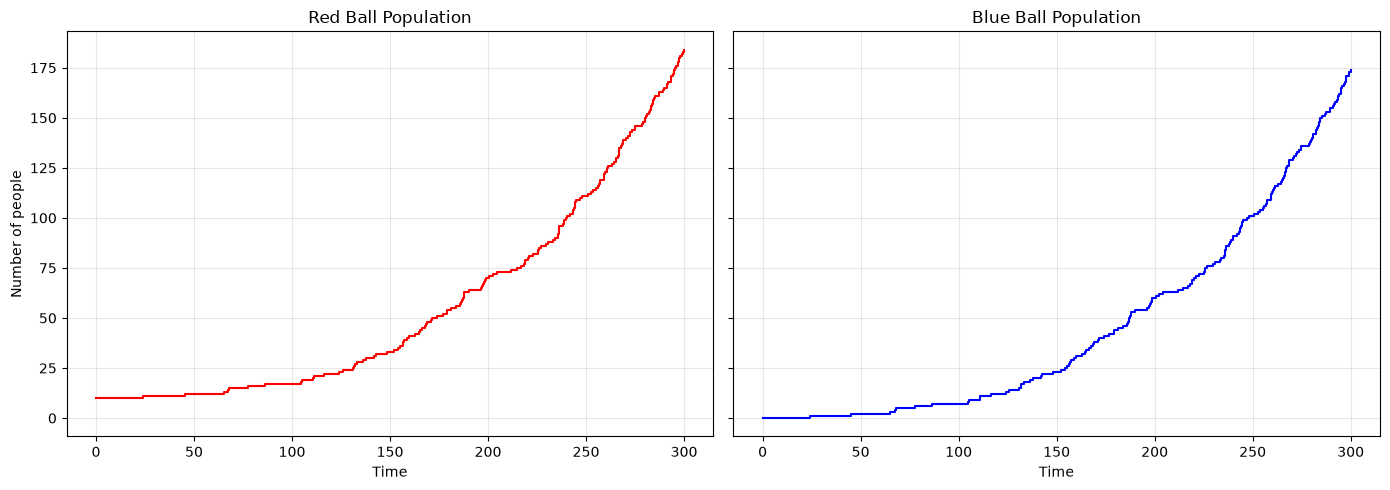

In [19]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Red population
axes[0].step(data["time"], data["R"], where="post", color="red")
axes[0].set_title("Red Ball Population")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Number of people")
axes[0].grid(alpha=0.3)

# Blue population
axes[1].step(data["time"], data["B"], where="post", color="blue")
axes[1].set_title("Blue Ball Population")
axes[1].set_xlabel("Time")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Comparision

Now we'll add our theoretical ODE solution to both graphs and compare it with the stochastic simulation.

Recall that our model is

$$
\begin{aligned}
S'(t)&=-2\beta R(t),\\
R'(t)&=\beta R(t),\\
B'(t)&=\beta R(t).
\end{aligned}
$$

We can solve the last two equations analytically:
$$
\boxed{R(t)=R_0e^{\beta t}}
$$

and, since $B'(t)=R'(t)$, this implies $\frac{d}{dt}\big(B(t)-R(t)\big)=0.$

So $B(t)-R(t)$ must be constant!


Using the initial conditions, $ B(t)-R(t)=B_0-R_0.$

Rearranging, $B(t)=R(t)+B_0-R_0.$

Since $R(t)=R_0e^{\beta t}$, we obtain

$$
\begin{aligned}
B(t)&=R_0e^{\beta t}+B_0-R_0\\
&=\boxed{B_0+R_0(e^{\beta t}-1).}
\end{aligned}
$$

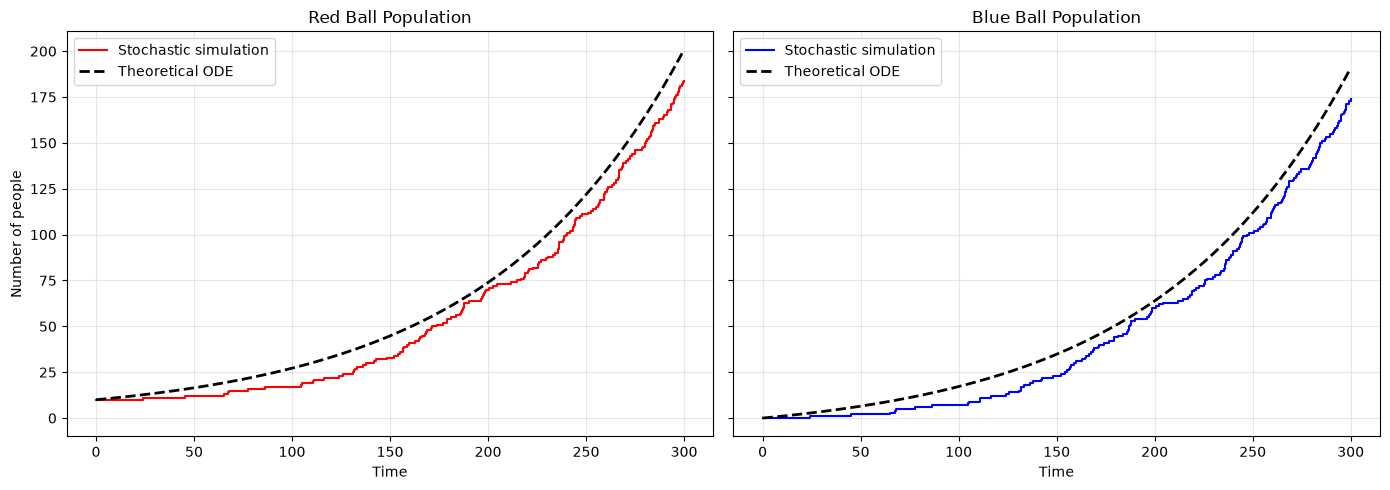

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Same parameters as our stochastic simulation
R0 = 10
B0 = 0
beta = 0.01

# Theoretical solutions
t = np.linspace(0, data["time"].max(), 1000)

R_theory = R0 * np.exp(beta * t)
B_theory = B0 + R0 * (np.exp(beta * t) - 1)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), sharey=True
)

# Red population
axes[0].step(
    data["time"], data["R"],
    where="post", color="red",
    label="Stochastic simulation"
)
axes[0].plot(
    t, R_theory,
    color="black", linestyle="--",
    linewidth=2, label="Theoretical ODE"
)
axes[0].set_title("Red Ball Population")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Number of people")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Blue population
axes[1].step(
    data["time"], data["B"],
    where="post", color="blue",
    label="Stochastic simulation"
)
axes[1].plot(
    t, B_theory,
    color="black", linestyle="--",
    linewidth=2, label="Theoretical ODE"
)
axes[1].set_title("Blue Ball Population")
axes[1].set_xlabel("Time")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
